Name Muhtasim Haque Nahian

Labpartner(s) Tahirunnisa Rahi

In [5]:
#import statements go here
#import statements go here
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs   #import map styles/types|
import cartopy.feature as cfeature  # features such as the ocean, coastlines rivers, etc
import cartopy.io.shapereader as shpreader     # to read shapefiles

# Class 7.1

Today we are going to go over cartopy a bit more and you will start the Pandas course in Datacamp.

I'm also going to go over the final project. Your topic (like a few sentances) is due this comeing Sunday 10/11

# Warmups 7.1

**W.1** Play around with some map projections in cartopy. 

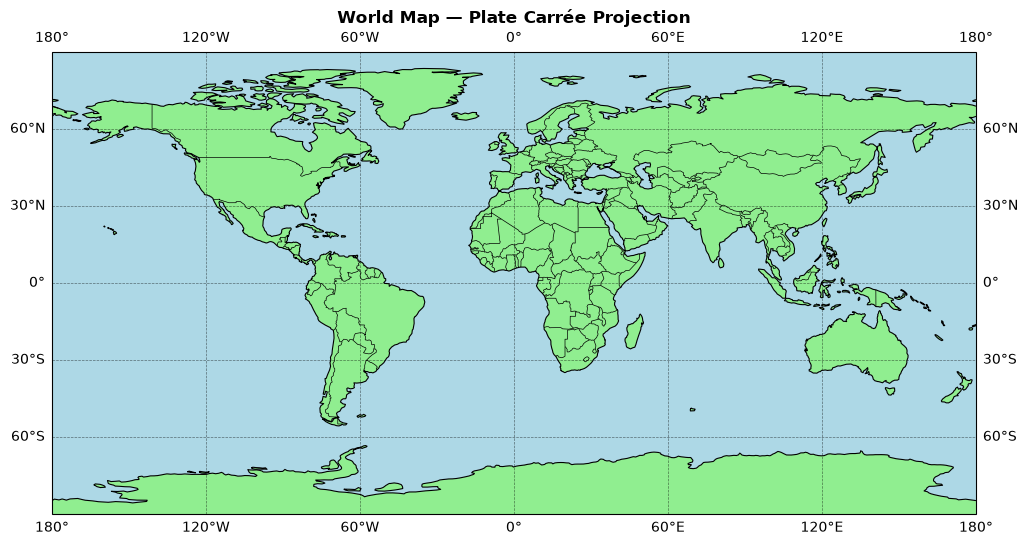

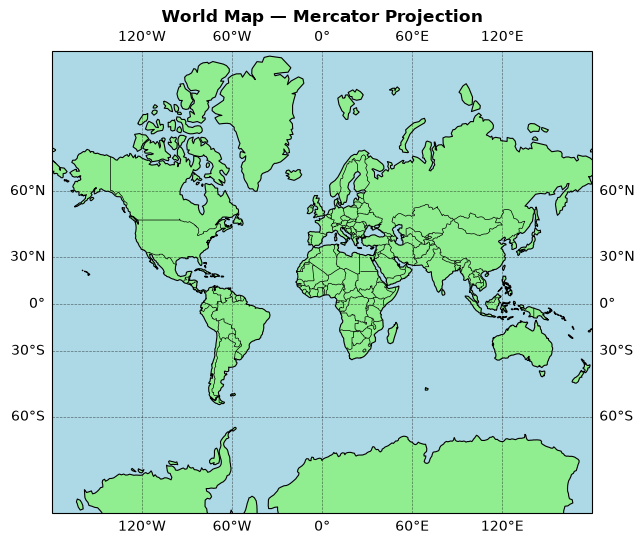

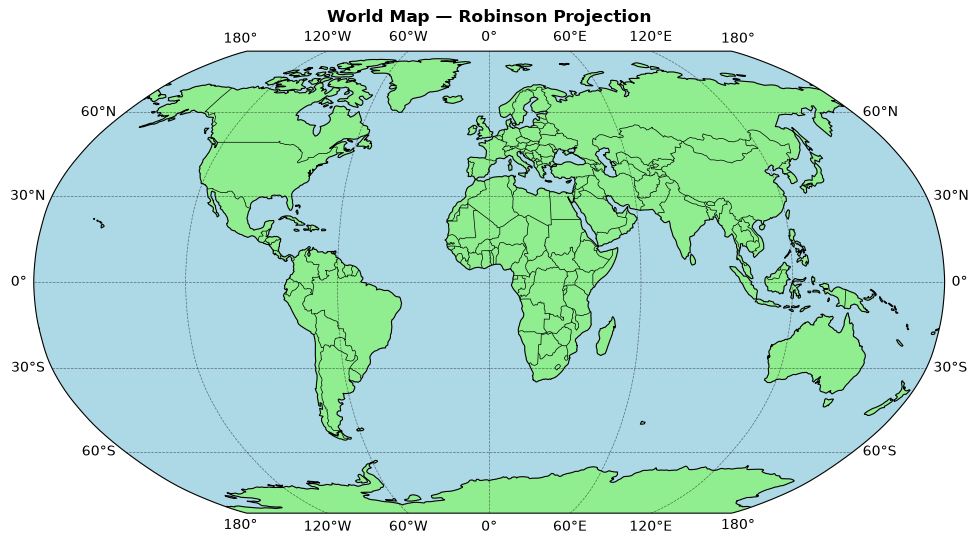

In [2]:
# loading different projection maps, trying different land, ocean, border features

projections = [("Plate Carrée", ccrs.PlateCarree()), ("Mercator", ccrs.Mercator()), ("Robinson", ccrs.Robinson())]

for name, projection in projections:

    fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={"projection": projection})

    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="lightgreen")
    ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
    ax.coastlines(linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.gridlines(draw_labels=True, color="black", linestyle="--", linewidth=0.5, alpha=0.5)
    ax.set_title(f"World Map — {name} Projection", fontweight="bold")

    plt.show()

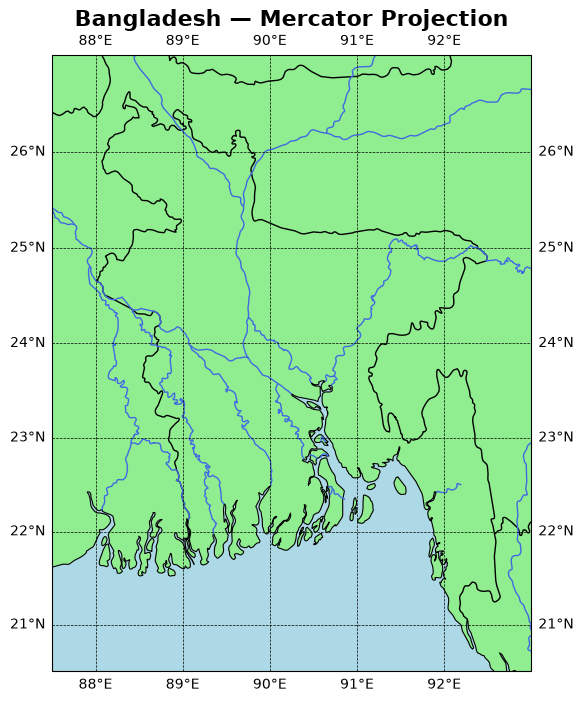

In [3]:
# creating a Mercator map centered near Bangladesh: changing resolution of the features to 10m

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": ccrs.Mercator(central_longitude=90)})

# Bangladesh
ax.set_extent([87.5, 93, 20.5, 27], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="lightblue")
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="lightgreen")
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=1)
ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="royalblue")
ax.gridlines(draw_labels=True, color="black", linestyle="--", linewidth=0.5, alpha=1)
ax.set_title("Bangladesh — Mercator Projection", fontsize=16, fontweight="bold")

plt.show()

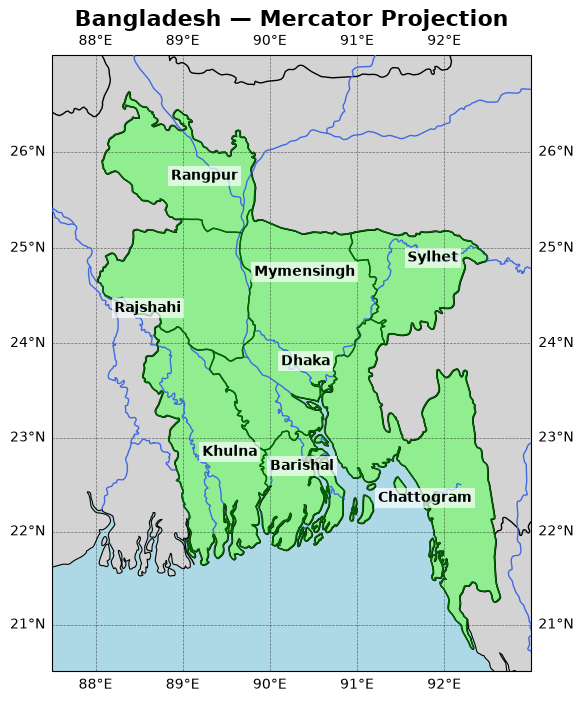

In [6]:
# here i have tried to highlight only Bangladesh, so greyed other countries. also i have labelled the divisions of Bangladesh

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": ccrs.Mercator(central_longitude=90)})

ax.set_extent([87.5, 93, 20.5, 27], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="lightblue")
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="lightgray")

# Read country boundaries and color Bangladesh light green
countries = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")

reader = shpreader.Reader(countries)

for country in reader.records():
    if country.attributes["ADMIN"] == "Bangladesh":
        ax.add_geometries([country.geometry], crs=ccrs.PlateCarree(), facecolor="lightgreen", edgecolor="black", linewidth=0.8, zorder=2)

reader.close()

ax.coastlines(resolution="10m", linewidth=0.8, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=1, zorder=3)
ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="royalblue", zorder=4)

# approx. coordinates: (longitude, latitude)
divisions = {"Dhaka": (90.41, 23.81), "Chattogram": (91.78, 22.36), "Rajshahi": (88.60, 24.37), "Khulna": (89.54, 22.85),
    "Barishal": (90.37, 22.70), "Sylhet": (91.87, 24.90), "Rangpur": (89.25, 25.75), "Mymensingh": (90.40, 24.75)}

# loading division boundaries
division_file = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_1_states_provinces")
division_reader = shpreader.Reader(division_file)

for division in division_reader.records():
    if division.attributes["admin"] == "Bangladesh":
        ax.add_geometries([division.geometry], crs=ccrs.PlateCarree(), facecolor="none", edgecolor="darkgreen", linewidth=1, zorder=4)

division_reader.close()

# adding division labels
for name, (lon, lat) in divisions.items():
    ax.text(lon, lat, name, fontsize=10, fontweight="bold", ha="center", va="center", transform=ccrs.PlateCarree(),
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.7, "pad": 2}, zorder=5)

ax.gridlines(draw_labels=True, color="black", linestyle="--", linewidth=0.5, alpha=0.5)
ax.set_title("Bangladesh — Mercator Projection", fontsize=16, fontweight="bold")

plt.show()

**W.2** Make a nice map of Antarctica. Label McMurdo Station

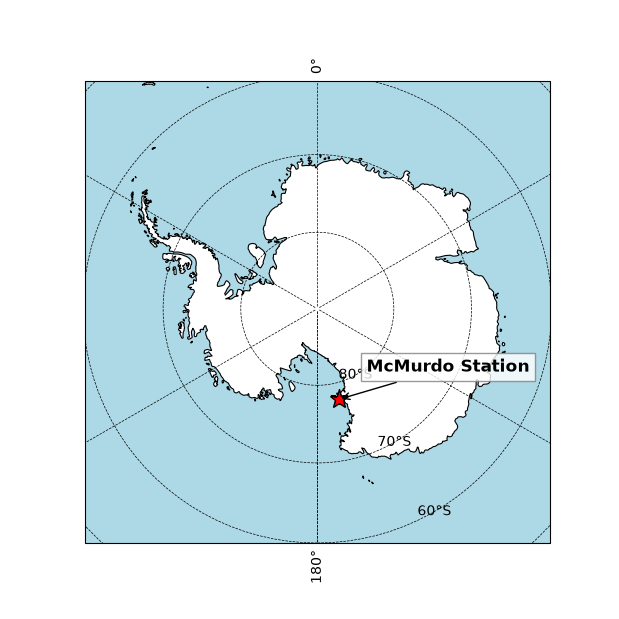

In [12]:
fig, ax = plt.subplots(figsize=(6, 6),subplot_kw={"projection": ccrs.SouthPolarStereo()})

ax.set_extent([-180, 180, -90, -60], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax.add_feature(cfeature.LAND, facecolor="white")
ax.coastlines(resolution="50m", linewidth=0.8)
ax.gridlines(draw_labels=True, color="black", linestyle="--", linewidth=0.5, alpha=1)

# McMurdo Station: approximately 77.85°S, 166.67°E
lon = 166.67
lat = -77.85

ax.plot(lon, lat, marker="*", markersize=14, color="red", markeredgecolor="black", transform=ccrs.PlateCarree())

# label the station with an offset
ax.annotate("McMurdo Station", xy=(lon, lat), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax), xytext=(20, 20), textcoords="offset points",
    fontsize=12, fontweight="bold", arrowprops={"arrowstyle": "->", "color": "black"}, bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "gray"})

ax.set_title("Antarctica — McMurdo Station", fontsize=16, fontweight="bold")

plt.show()

# Lecture 7.1

### Agenda:

- Questions
- Final project (see github for rubrics, and 2024 class for samples)
    - Project topics due this Sunday 10/11. I will discuss this with you to make sure it's not overly ambitious.
    - Proposal due 10/25. We will do peer review on this
    - Topics presentations 10/26, we will give feedback
    - Weekly reports become project focused in a few weeks
    - Final report is due 12/10
    - Final presentation during Final period 12/11 12:30-2:30
  

### Questions

# Lab 7.1

**E.1** Complete Data Manipulation with Pandas Ch 1-2 in datacamp. I'm assigning all of this course to the class, as many of you have .csv type data that works well with Pandas. If you don't have data that Pandas is useful for, come see me and we can talk about an alternate assignment.


**E.2** Make notes for yourself on progamming tecniques and commands you learned in the datacamp chapter above, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

## ch 1

### Inspecting a DataFrame

<span style="color:yellow;">***.head()***</span> returns the first few rows (the “head” of the DataFrame).

<span style="color:yellow;">***.info()***</span> shows information on each of the columns, such as the data type and number of missing values.

<span style="color:yellow;">***.shape***</span> returns the number of rows and columns of the DataFrame.

<span style="color:yellow;">***.describe()***</span> calculates a few summary statistics for each column.

### Parts of a DataFrame

**values:** A two-dimensional NumPy array, accessed via the <span style="color:yellow;">***.to_numpy()***</span> method.

**columns:** An index of column names, accessed via the <span style="color:yellow;">***.columns***</span> attribute.

**index:** An index for the rows, accessed via the <span style="color:yellow;">***.index***</span> attribute.


### Sorting rows

Sort the rows by passing a column name to ***.sort_values().***

<table style="margin-left:0; margin-right:auto;">
    <tr><th>Sort on</th><th>Example</th></tr>
    <tr><td>one column</td><td><span style="color:green;">df.sort_values("breed")</span></td></tr>
    <tr><td>multiple columns</td><td><span style="color:green;">df.sort_values(["breed", "weight_kg"])</span></td></tr>
</table>


### Ascending/descending

<table style="margin-left:0; margin-right:auto;">
    <tr><th>Sort on</th><th>Example</th></tr>
    <tr><td>one column</td><td><span style="color:green;">df.sort_values("breed", ascending=False)</span></td></tr>
    <tr><td>multiple columns</td><td><span style="color:green;">df.sort_values(["breed", "weight_kg"], ascending=[True, False])</span></td></tr>
</table>

### Subsetting columns

<span style="color:green;">df[["col_a", "col_b"]]</span>

### Subsetting rows

<span style="color:green;">dogs[(dogs["height_cm"] > 60) & (dogs["color"] == "tan")]</span>


### Subsetting rows by categorical variables

<span style="color:green;">colors = ["brown", "black", "tan"]</span>
<span style="color:green;">condition = dogs[dogs["color"].isin(colors)]</span>


### Adding new columns

<span style="color:green;">homelessness["p_homeless"] = homelessness["total"] / homelessness["state_pop"]</span>

## ch 2

### Mean and median

<span style="color:green;">sales["weekly_sales"].mean()</span>

<span style="color:green;">sales["weekly_sales"].median()</span>


### Max and mean

<span style="color:green;">sales["date"].max()</span>

<span style="color:green;">sales["date"].min()</span>


### Use own custom function using .agg()

<span style="color:green;">def iqr(column):
    return column.quantile(0.75) - column.quantile(0.25)</span>

<table style="margin-left:0; margin-right:auto;">
    <tr><th>Sort on</th><th>Example</th></tr>
    <tr><td>one column</td><td><span style="color:green;">sales["temperature_c"].agg(iqr)</span></td></tr>
    <tr><td>multiple columns</td><td><span style="color:green;">sales[["temperature_c", "fuel_price_usd_per_l", "unemployment"]].agg(iqr)</span></td></tr>
    <tr><td>add median in the order</td><td><span style="color:green;">dsales[["temperature_c", "fuel_price_usd_per_l", "unemployment"]].agg([iqr, "median"])</span></td></tr>
</table>


### Cumulative sum and cumulative max

<span style="color:green;">sales_1_1["cum_weekly_sales"] = sales_1_1["weekly_sales"].cumsum()</span>
<span style="color:green;">sales_1_1["cum_max_sales"] = sales_1_1["weekly_sales"].cummax()</span>


### Dropping duplicates from a column

<span style="color:green;">store_types = sales.drop_duplicates(subset=["store", "type"])</span>


### Counting numbers

<span style="color:green;">store_counts = store_types["type"].value_counts()</span>


### Counting proportions

<span style="color:green;">store_props = store_types["type"].value_counts(normalize=True)</span>


### Mean by pivoting on the variable

<span style="color:green;">mean_sales_by_type = sales.pivot_table(values="weekly_sales", index="type")</span>


### Mean, median by pivoting

<span style="color:green;">mean_med_sales_by_type = sales.pivot_table(values="weekly_sales", index="type", aggfunc=["mean", "median"])</span>

**E.3** Work on brainstorming your final project. Make sure it's actually doable, please don't take on too much! The goal here is to learn some code and practice scientific communication.